# 03 — K-Means berbasis skor TOPSIS
Input: `data/dki_master.csv` + `data/topsis_result.csv` · Output: `data/clustered_result.csv`

## 1. Setup & load data

In [1]:
import warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, geopandas as gpd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

ROOT = Path(".."); DATA = ROOT/"data"; FIG = DATA/"figures"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

master = pd.read_csv(DATA/"dki_master.csv", index_col="kecamatan")
topsis = pd.read_csv(DATA/"topsis_result.csv"); topsis["kecamatan"] = topsis.kecamatan.str.strip().str.upper(); topsis = topsis.set_index("kecamatan")

base = master.drop(index=[k for k in master.index if "SERIBU" in k])      # 42 kecamatan (sama dengan TOPSIS)
base = base.join(topsis[["skor_topsis","rank_topsis"]], how="left")
assert base.skor_topsis.notna().all(), f"kecamatan tanpa skor TOPSIS: {base.index[base.skor_topsis.isna()].tolist()}"
print(base.shape, "| skor TOPSIS cocok 42/42")

(42, 21) | skor TOPSIS cocok 42/42


## 2. Pilih fitur & preprocessing
`skor_topsis` merangkum 8 kriteria risiko dan menjadi sumbu utama klaster. Fitur pendamping mewakili **dampak ke warga** (`jiwa_per_1000`) dan **paparan penduduk** (`kepadatan_jiwa_km2`).

Catatan metodologis: kedua fitur ini juga kriteria TOPSIS, jadi ada tumpang-tindih yang disengaja. Alternatif tanpa tumpang-tindih (`frek_tahun_banjir`, `kejadian_per_tahun`, `tinggi_med_cm`, `pertumbuhan_pddk_15_19`) diuji dan membuat klaster tidak konsisten dengan peringkat TOPSIS (kecamatan peringkat 1 jatuh ke klaster "Menengah"; hanya 7/10 kecamatan top-10 masuk klaster tertinggi).

In [2]:
CAND = ["skor_topsis",            # hasil SPK
        "jiwa_per_1000",          # dampak ke warga
        "kepadatan_jiwa_km2"]     # paparan penduduk
X = base[CAND].copy(); X = X.fillna(X.median()); print(X.describe().T.round(2))

                    count      mean       std      min       25%       50%       75%       max
skor_topsis          42.0      0.60      0.12     0.16      0.63      0.64      0.66      0.83
jiwa_per_1000        42.0     14.29     18.47     0.00      1.16      7.51     19.61     82.71
kepadatan_jiwa_km2   42.0  21184.53  11029.30  8824.66  14085.35  19357.48  23165.39  61408.89


outlier: {'skor_topsis': 13, 'jiwa_per_1000': 4, 'kepadatan_jiwa_km2': 4}
log1p: ['jiwa_per_1000', 'kepadatan_jiwa_km2']
dibuang (r>0.9): []
FEATURES: ['skor_topsis', 'jiwa_per_1000', 'kepadatan_jiwa_km2']


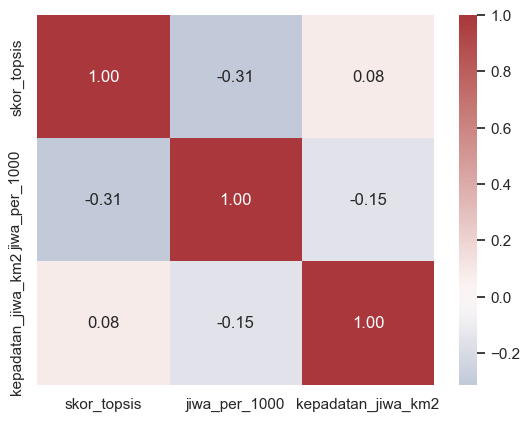

In [3]:
q1, q3 = X.quantile(.25), X.quantile(.75); out = (X < q1-1.5*(q3-q1)) | (X > q3+1.5*(q3-q1))
print("outlier:", out.sum()[out.sum() > 0].to_dict())

LOG = [k for k in X.columns if k != "skor_topsis" and X[k].skew() > 1 and (X[k] >= 0).all()]
Xt = X.copy(); Xt[LOG] = np.log1p(Xt[LOG]); print("log1p:", LOG)
for k in X.columns[out.any()]:
    if k != "skor_topsis": lo, hi = Xt[k].quantile([.05, .95]); Xt[k] = Xt[k].clip(lo, hi)       # winsorize 5%

cr = Xt.corr().abs(); drop = set()
for i, a_ in enumerate(cr.columns):
    for b_ in cr.columns[i+1:]:
        if cr.loc[a_, b_] > 0.90 and a_ not in drop and b_ not in drop: drop.add(b_)
FEATURES = [k for k in Xt.columns if k not in drop]; print("dibuang (r>0.9):", sorted(drop)); print("FEATURES:", FEATURES)

Z = pd.DataFrame(StandardScaler().fit_transform(Xt[FEATURES]), index=Xt.index, columns=FEATURES)
sns.heatmap(Xt[FEATURES].corr(), annot=True, fmt=".2f", cmap="vlag", center=0); plt.show()

## 3. Pilih k
Selain metrik internal, tiap k dinilai pada hal yang relevan untuk keputusan mitigasi: (1) ukuran klaster tidak terlalu kecil/dominan, (2) urutan klaster sejalan dengan peringkat TOPSIS (`spearman_rank`), (3) kestabilan terhadap algoritma lain (`ARI_vs_ward`). $k=4$ dipertahankan sebagai 4 tingkat prioritas kebijakan bila lolos aturan kelayakan dan silhouette-nya mendekati yang terbaik.

,inertia,silhouette,DBI,CH,spearman_rank,top10_di_klaster0,ukuran_min,ukuran_maks,ARI_vs_ward
k,,,,,,,,,
2,81.059,0.388,1.031,22.177,0.738,10,10,32,1.000
3,53.506,0.383,0.929,26.420,0.766,9,9,23,0.856
4,40.349,0.354,0.874,26.888,0.902,10,7,15,0.574
5,32.321,0.369,0.923,26.811,0.901,10,5,15,0.536
6,25.588,0.378,0.853,28.254,0.899,7,5,10,0.870
7,21.199,0.385,0.707,28.839,0.907,7,1,11,0.859


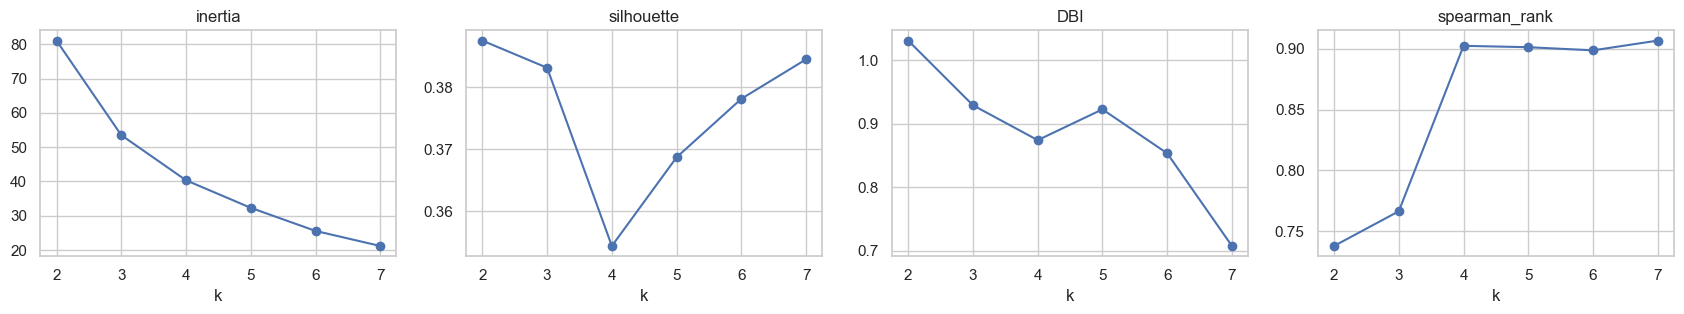

k yang memenuhi aturan kelayakan: [4, 5, 6] | silhouette tertinggi di antaranya: k = 6


In [4]:
from scipy.stats import spearmanr

def order_labels(lab):
    """Relabel: id 0 = rata-rata skor TOPSIS tertinggi ... id K-1 = terendah."""
    order = pd.Series(base.skor_topsis.values).groupby(lab).mean().sort_values(ascending=False).index.tolist()
    return np.array([order.index(l) for l in lab])

TOP10 = (base.rank_topsis <= 10).values
rows = []
for k in range(2, 8):
    l = KMeans(k, n_init=50, random_state=SEED).fit(Z); lab = order_labels(l.labels_); sz = np.bincount(lab)
    rows.append(dict(k=k, inertia=l.inertia_, silhouette=silhouette_score(Z, lab), DBI=davies_bouldin_score(Z, lab), CH=calinski_harabasz_score(Z, lab),
                     spearman_rank=spearmanr(lab, base.rank_topsis)[0], top10_di_klaster0=int((lab[TOP10] == 0).sum()),
                     ukuran_min=sz.min(), ukuran_maks=sz.max(), ARI_vs_ward=adjusted_rand_score(lab, AgglomerativeClustering(k).fit_predict(Z))))
sel = pd.DataFrame(rows).set_index("k"); display(sel.round(3))
fig, ax = plt.subplots(1, 4, figsize=(17, 3.3))
for i, k in enumerate(["inertia", "silhouette", "DBI", "spearman_rank"]): sel[k].plot(marker="o", ax=ax[i], title=k)
plt.tight_layout(); plt.savefig(FIG/"pilih_k.png", dpi=200); plt.show()

# aturan kelayakan: klaster tidak kecil (>=5), tidak mendominasi (<=40% data), urutan klaster sejalan dengan rank TOPSIS (rho >= 0.8)
ok = sel[(sel.ukuran_min >= 5) & (sel.ukuran_maks <= .40 * len(Z)) & (sel.spearman_rank >= .80)]
print("k yang memenuhi aturan kelayakan:", ok.index.tolist(), "| silhouette tertinggi di antaranya: k =", ok.silhouette.idxmax() if len(ok) else None)

## 4. K-Means final & validasi

In [5]:
K_FINAL = 4
km = KMeans(K_FINAL, n_init=100, random_state=SEED).fit(Z)

# urutkan cluster: id 0 = rata-rata skor TOPSIS tertinggi (risiko tertinggi) ... id K-1 = terendah
labels = order_labels(km.labels_); centers = np.array([Z.values[labels == c].mean(0) for c in range(K_FINAL)])

res = base.copy(); res["cluster_id"] = labels; res["silhouette_sample"] = silhouette_samples(Z, labels)
print(f"silhouette={silhouette_score(Z, labels):.3f}  DBI={davies_bouldin_score(Z, labels):.3f}  CH={calinski_harabasz_score(Z, labels):.1f}")
print("ukuran:", res.cluster_id.value_counts().sort_index().to_dict(), "| silhouette<0:", res.index[res.silhouette_sample < 0].tolist())

ari = [adjusted_rand_score(km.labels_, KMeans(K_FINAL, n_init=10, random_state=s).fit_predict(Z)) for s in range(20)]
rg = np.random.default_rng(SEED); bt = []
for _ in range(100):
    ix = rg.choice(len(Z), int(.8*len(Z)), replace=False); bt.append(adjusted_rand_score(km.labels_[ix], KMeans(K_FINAL, n_init=10, random_state=0).fit_predict(Z.iloc[ix])))
print(f"ARI seed={np.mean(ari):.2f} (min {np.min(ari):.2f}) | ARI bootstrap={np.mean(bt):.2f}")

silhouette=0.351  DBI=0.880  CH=27.0
ukuran: {0: 14, 1: 11, 2: 7, 3: 10} | silhouette<0: []
ARI seed=0.91 (min 0.81) | ARI bootstrap=0.74


### Validasi tambahan: konsistensi dengan TOPSIS, per-klaster, dan algoritma pembanding

In [6]:
rho = spearmanr(labels, base.rank_topsis)[0]
print(f"Spearman(klaster, rank TOPSIS) = {rho:.2f} | top-10 TOPSIS di klaster 0/1: {int((labels[TOP10] <= 1).sum())}/10 (klaster 0: {int((labels[TOP10] == 0).sum())}/10)")
assert rho >= .70, "urutan klaster tidak sejalan dengan peringkat TOPSIS"

sil_k = res.groupby("cluster_id").silhouette_sample.agg(["mean", "min", "count"]).round(3); display(sil_k)
print("kecamatan batas (silhouette < 0.1):", res.index[res.silhouette_sample < .1].tolist())

ward = AgglomerativeClustering(K_FINAL).fit_predict(Z); gmm = GaussianMixture(K_FINAL, n_init=10, random_state=SEED).fit_predict(Z)
print(f"ARI K-Means vs Ward = {adjusted_rand_score(labels, ward):.2f} | vs GMM = {adjusted_rand_score(labels, gmm):.2f}")
q = pd.qcut(base.rank_topsis, K_FINAL, labels=False)
print("kecamatan yang bergeser > 1 tingkat dari kuartil rank TOPSIS-nya:", res.index[np.abs(labels - q.values) > 1].tolist() or "tidak ada")

Spearman(klaster, rank TOPSIS) = 0.90 | top-10 TOPSIS di klaster 0/1: 10/10 (klaster 0: 10/10)


,mean,min,count
cluster_id,,,
0,0.333,0.083,14
1,0.348,0.002,11
2,0.486,0.210,7
3,0.283,0.091,10


kecamatan batas (silhouette < 0.1): ['GROGOL PETAMBURAN', 'CEMPAKA PUTIH', 'KEBAYORAN LAMA', 'CAKUNG', 'KELAPA GADING']
ARI K-Means vs Ward = 0.61 | vs GMM = 0.54
kecamatan yang bergeser > 1 tingkat dari kuartil rank TOPSIS-nya: tidak ada


## 5. Profil & nama cluster
Cluster diurutkan dari rata-rata `skor_topsis` tertinggi. Ubah `LABEL` kalau perlu.

In [7]:
from matplotlib.colors import LinearSegmentedColormap, to_hex
LABEL = ["Prioritas Tinggi", "Waspada", "Menengah", "Rendah"][:K_FINAL]
RAMP  = LinearSegmentedColormap.from_list("risiko", ["#8B0000", "#E4572E", "#F6C85F", "#B7E4A7"])      # merah tua (tinggi) -> hijau muda (rendah)
COLORS = {LABEL[i]: to_hex(RAMP(i / max(K_FINAL - 1, 1))) for i in range(K_FINAL)}
CLUSTER_NAMES = {i: LABEL[i] for i in range(K_FINAL)}; res["cluster_name"] = res.cluster_id.map(CLUSTER_NAMES)

PROF = ["skor_topsis","rank_topsis","frek_tahun_banjir","bulan_banjir_per_tahun","tinggi_max_cm","jiwa_per_1000","kepadatan_jiwa_km2","pertumbuhan_pddk_15_19"]
prof = res.groupby("cluster_id")[PROF].mean().round(2); prof.insert(0, "nama", [CLUSTER_NAMES[i] for i in prof.index]); prof["n"] = res.cluster_id.value_counts().sort_index()
display(prof.style.apply(lambda r: [f"background-color: {COLORS[r['nama']]}" if c_ == "nama" else "" for c_ in r.index], axis=1))
for cid in range(K_FINAL): print(f"{cid} {CLUSTER_NAMES[cid]}:", ", ".join(res[res.cluster_id == cid].sort_values("rank_topsis").index))

,nama,skor_topsis,rank_topsis,frek_tahun_banjir,bulan_banjir_per_tahun,tinggi_max_cm,jiwa_per_1000,kepadatan_jiwa_km2,pertumbuhan_pddk_15_19,n
cluster_id,,,,,,,,,,
0,Prioritas Tinggi,0.690000,7.710000,0.890000,3.040000,183.210000,16.340000,17867.790000,0.080000,14
1,Waspada,0.640000,22.910000,0.760000,1.720000,132.730000,1.630000,15407.150000,0.020000,11
2,Menengah,0.630000,24.000000,0.640000,0.960000,102.140000,1.590000,39813.810000,0.050000,7
3,Rendah,0.410000,37.500000,1.000000,5.750000,272.000000,34.230000,19142.590000,0.020000,10


0 Prioritas Tinggi: KEBON JERUK, TANJUNG PRIOK, TANAH ABANG, PENJARINGAN, CILANDAK, SAWAH BESAR, PALMERAH, CILINCING, MAMPANG PRAPATAN, PESANGGRAHAN, CIRACAS, KALI DERES, CAKUNG, PULO GADUNG
1 Waspada: KELAPA GADING, PASAR REBO, GROGOL PETAMBURAN, JAGAKARSA, CIPAYUNG, DUREN SAWIT, PADEMANGAN, SETIA BUDI, GAMBIR, CEMPAKA PUTIH, MENTENG
2 Menengah: MATRAMAN, KOJA, TAMBORA, KEMAYORAN, TAMAN SARI, JOHAR BARU, SENEN
3 Rendah: TEBET, KRAMAT JATI, PANCORAN, KEMBANGAN, KEBAYORAN BARU, PASAR MINGGU, KEBAYORAN LAMA, CENGKARENG, JATINEGARA, MAKASAR


## 6. Visualisasi

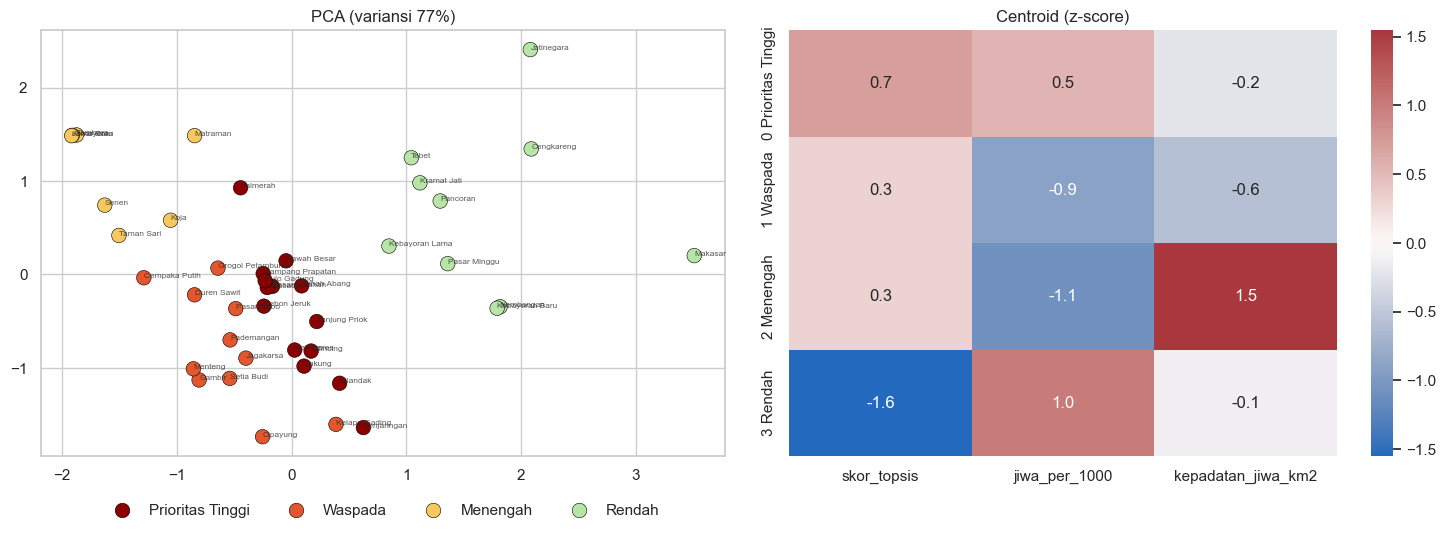

In [8]:
P = PCA(2, random_state=SEED).fit(Z); pc = P.transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(x=pc[:,0], y=pc[:,1], hue=res.cluster_name.values, palette=COLORS, hue_order=LABEL, s=110, edgecolor="black", linewidth=.4, ax=ax[0])
for i, n in enumerate(res.index): ax[0].annotate(n.title(), (pc[i,0], pc[i,1]), fontsize=6, alpha=.75)
ax[0].set_title(f"PCA (variansi {P.explained_variance_ratio_.sum():.0%})"); ax[0].legend(loc="upper center", bbox_to_anchor=(.5, -0.08), ncol=K_FINAL, frameon=False)
cen = pd.DataFrame(centers, columns=Z.columns, index=[f"{i} {LABEL[i]}" for i in range(K_FINAL)])
sns.heatmap(cen, annot=True, fmt=".1f", cmap="vlag", center=0, ax=ax[1]); ax[1].set_title("Centroid (z-score)")
plt.tight_layout(); plt.savefig(FIG/"cluster_pca_centroid.png", dpi=200); plt.show()

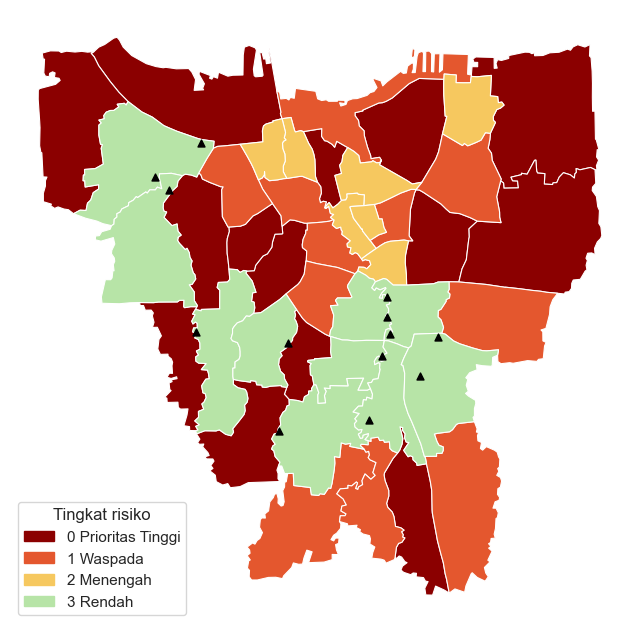

In [9]:
from matplotlib.patches import Patch
pol = gpd.read_file(DATA/"interim/kecamatan_poly.geojson").merge(res.reset_index()[["kecamatan","cluster_name"]], on="kecamatan", how="left")
fig, ax = plt.subplots(figsize=(8, 8))
for name in LABEL: pol[pol.cluster_name == name].plot(ax=ax, color=COLORS[name], edgecolor="white", linewidth=.8)
pol[pol.cluster_name.isna()].plot(ax=ax, color="lightgrey", edgecolor="white")
al = pd.read_csv(DATA/"interim/alat_dini_titik.csv"); gpd.GeoDataFrame(al, geometry=gpd.points_from_xy(al.lon, al.lat), crs=4326).plot(ax=ax, color="black", marker="^", markersize=25)
ax.legend(handles=[Patch(color=COLORS[n], label=f"{i} {n}") for i, n in enumerate(LABEL)], title="Tingkat risiko", loc="lower left"); ax.set_axis_off()
plt.savefig(FIG/"cluster_map.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Export

In [10]:
out = res.reset_index()[["kecamatan","cluster_id","cluster_name","silhouette_sample","skor_topsis","rank_topsis"]].sort_values("rank_topsis")
out.to_csv(DATA/"clustered_result.csv", index=False, encoding="utf-8")
res.to_csv(DATA/"interim/dki_master_clustered.csv", encoding="utf-8"); print(out.shape); out.head(10)

(42, 6)


,kecamatan,cluster_id,cluster_name,silhouette_sample,skor_topsis,rank_topsis
3,KEBON JERUK,0,Prioritas Tinggi,0.395497,0.832322,1
41,TANJUNG PRIOK,0,Prioritas Tinggi,0.515355,0.717263,2
15,TANAH ABANG,0,Prioritas Tinggi,0.526764,0.707320,3
40,PENJARINGAN,0,Prioritas Tinggi,0.218579,0.692689,4
16,CILANDAK,0,Prioritas Tinggi,0.346288,0.685469,5
13,SAWAH BESAR,0,Prioritas Tinggi,0.495030,0.674210,6
5,PALMERAH,0,Prioritas Tinggi,0.119361,0.674144,7
36,CILINCING,0,Prioritas Tinggi,0.340629,0.666021,8
20,MAMPANG PRAPATAN,0,Prioritas Tinggi,0.405192,0.664510,9
23,PESANGGRAHAN,0,Prioritas Tinggi,0.426618,0.663929,10


In [ ]:
# Ekspor untuk 04_viz (matriks fitur terstandar & tabel pemilihan k)
Z.to_csv(DATA/"interim/cluster_features_z.csv"); sel.to_csv(DATA/"interim/kmeans_sweep.csv")
print("tersimpan: cluster_features_z.csv, kmeans_sweep.csv")